# Classical subtropical Stommel gyre

This example computes the planetary-geostrophic analogue of a classical Stommel subtropical gyre. A flat rectangular basin on a beta plane is forced by a zonal wind stress with negative curl throughout the interior. Buoyancy forcing is zero, so the circulation is barotropic and the solution isolates the Sverdrup interior and frictional western boundary current.

With the convention $(U,V)=(-\partial_y\Psi,\partial_x\Psi)$, the inviscid interior satisfies

$$\beta V = \hat{\boldsymbol z}\mathbin{\boldsymbol\cdot}(\boldsymbol\nabla\mathbin{\boldsymbol\times}\boldsymbol\tau),$$

while the analytical PG bottom stress closes the circulation near the basin boundary.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", "PlanetaryGeostrophy"))
using PlanetaryGeostrophy
using Plots

  Activating project at `~/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy`


## Basin and forcing

The wind changes from westward at the southern boundary to eastward at the northern boundary. Its curl is negative between the boundaries, producing a single anticyclonic subtropical gyre.

In [2]:
Lx, Ly = 2.0, 1.0
H0 = 1.0
f0, beta = 1.0, 0.30
Ek, Γ = 0.01, 0.20
tau0 = 5e-4

eta(y) = (y + Ly / 2) / Ly
tau_x(x, y) = -tau0 * cos(pi * eta(y))
tau_y(x, y) = 0.0
wind_curl(x, y) = -tau0 * pi / Ly * sin(pi * eta(y))

problem = PGProblem(
    parameters=PGParameters(Ek, Γ; viscosity=1.0, diffusivity=1.0),
    depth=(x, y) -> H0,
    depth_x=(x, y) -> 0.0,
    depth_y=(x, y) -> 0.0,
    coriolis=(x, y) -> f0 + beta * y,
    coriolis_x=(x, y) -> 0.0,
    coriolis_y=(x, y) -> beta,
    wind_stress=(x, y) -> tau_x(x, y) + im * tau_y(x, y),
    restoring_buoyancy=(x, y, z) -> 0.0,
    surface_buoyancy=(x, y) -> 0.0,
    boundary=rectangle_boundary(Lx, Ly),
)

PGProblem{PGParameters{Float64}, var"#31#32", var"#37#38", var"#39#40", var"#41#42", var"#43#44", var"#45#46", var"#47#48", var"#33#34", var"#35#36", Vector{Tuple{Float64, Float64}}, PlanetaryGeostrophy.var"#78#79"{Vector{Tuple{Float64, Float64}}}}(PGParameters{Float64}(0.01, 0.2, 1.0, 1.0), var"#31#32"(), var"#37#38"(), var"#39#40"(), var"#41#42"(), var"#43#44"(), var"#45#46"(), var"#47#48"(), var"#33#34"(), var"#35#36"(), [(-1.0, -0.5), (1.0, -0.5), (1.0, 0.5), (-1.0, 0.5)], PlanetaryGeostrophy.var"#78#79"{Vector{Tuple{Float64, Float64}}}([(-1.0, -0.5), (1.0, -0.5), (1.0, 0.5), (-1.0, 0.5)]), 1.0e-5)

## Surface-pressure and transport solution

In [3]:
solution = solve_pg(
    problem;
    mesh_file=joinpath(@__DIR__, "stommel_pg_pressure.msh"),
    mesh_resolution=0.06,
    pressure_order=2,
    overwrite_mesh=true,
)
display(performance_summary(solution))

┌ Info: PG solve started
│   Ek = 0.01
│   Γ = 0.2
│   viscosity = 1.0
│   diffusivity = 1.0
│   pressure_order = 2
│   mesh_resolution = 0.06
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/stommel_pg_pressure.msh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:204
┌ Info: Starting generating surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16


Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000150208s, CPU 0.00014s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.0101565s, CPU 0.010035s)
Info    : 735 nodes 1472 elements
Info    : Writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/stommel_pg_pressure.msh'...
Info    : Done writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/stommel_pg_pressure.msh'
Info    : Reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/Pla

┌ Info: Completed generating surface mesh
│   seconds = 0.058
│   allocated_mib = 3.54
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Starting loading analytical Green-function kernels
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed loading analytical Green-function kernels
│   seconds = 0.0
│   allocated_mib = 0.0
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Surface-pres

(mesh = (seconds = 0.058394542, allocated_mib = 3.535980224609375, gc_seconds = 0.0), kernels = (seconds = 4.1e-8, allocated_mib = 0.0, gc_seconds = 0.0), surface_pressure = (mesh_load = (seconds = 2.604183875, allocated_mib = 618.8058929443359, gc_seconds = 0.068927125), finite_element_setup = (seconds = 3.397266458, allocated_mib = 1765.046890258789, gc_seconds = 0.269701793), operator_assembly = (seconds = 44.207311583, allocated_mib = 3973.957015991211, gc_seconds = 0.354868793), linear_solve = (seconds = 0.101375875, allocated_mib = 32.24510192871094, gc_seconds = 0.008324959), total_seconds = 51.27291202545166), total_seconds = 51.38016605377197)

In [4]:
# Stay just inside the finite-element boundary for point evaluation.
x = range(-0.99Lx / 2, 0.99Lx / 2; length=49)
y = range(-0.99Ly / 2, 0.99Ly / 2; length=33)
diagnostics = compute_diagnostics(solution, x, y)
display(performance_summary(diagnostics))

┌ Info: PG diagnostic calculation started
│   Nx = 49
│   Ny = 33
│   horizontal_points = 1617
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:818
┌ Info: Transport streamfunction solve started
│   finite_element_order = 2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/SurfacePressureTools.jl:241
┌ Info: Starting constructing streamfunction finite-element spaces
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/SurfacePressureTools.jl:12
┌ Info: Completed constructing streamfunction finite-element spaces
│   seconds = 

(streamfunction = (finite_element_setup = (seconds = 0.98556375, allocated_mib = 497.55445861816406, gc_seconds = 0.042191333), current_projection = (seconds = 11.226671083, allocated_mib = 6519.0772705078125, gc_seconds = 0.36444921), operator_assembly = (seconds = 2.840876333, allocated_mib = 363.36395263671875, gc_seconds = 0.01319475), linear_solve = (seconds = 0.032184833, allocated_mib = 5.283172607421875, gc_seconds = 0.018305167), total_seconds = 15.149433135986328), sampling = (seconds = 2.694953459, allocated_mib = 1989.286880493164, gc_seconds = 0.084670209), total_seconds = 18.24426293373108, wet_points = 1617, points_per_second = 600.0103618115952, transport_projection_relative_l2 = 0.32380956418189705)

## PG diagnostics

The transport vectors and streamfunction show the broad Sverdrup interior and narrow western return current. Bottom stress supplies the vorticity needed to close the gyre.

┌ Info: Plotting bottom stress
│   stride = 4
│   arrow_scale = 0.15
│   arrowhead_size = 0.08
│   output = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/stommel_pg_bottom_stress.png
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1381
┌ Info: Starting rendering bottom-stress plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed rendering bottom-stress plot
│   seconds = 0.569
│   allocated_mib = 216.87
│   gc_seconds = 0.014
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive

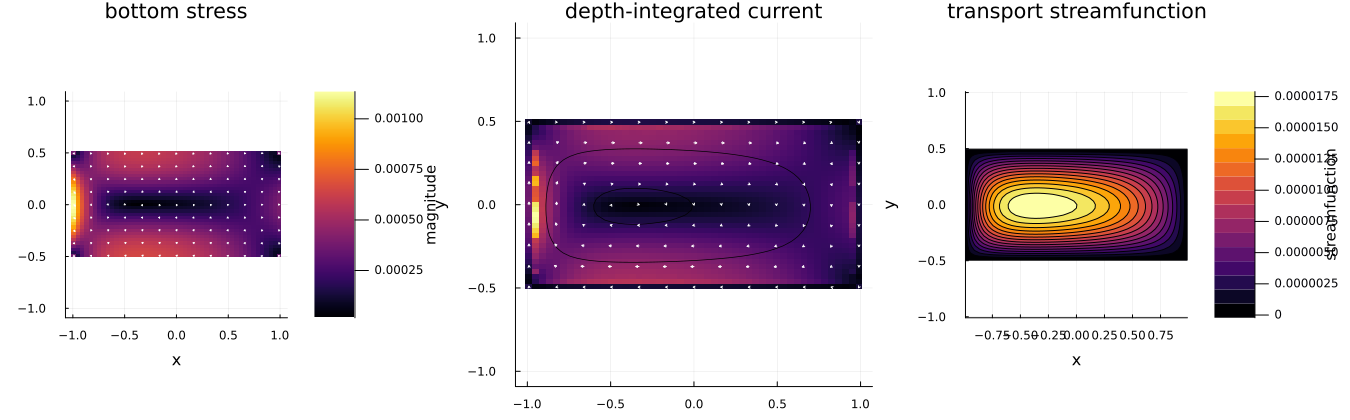

In [5]:
bottom_stress_figure = plot_bottom_stress(
    diagnostics;
    arrow_scale=0.15,
    output=joinpath(@__DIR__, "stommel_pg_bottom_stress.png"),
)
transport_figure = plot_depth_integrated_current(
    diagnostics;
    arrow_scale=0.15,
    output=joinpath(@__DIR__, "stommel_pg_transport.png"),
)
streamfunction_figure = plot_streamfunction(
    diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_streamfunction.png"),
)
diagnostic_figure = plot_diagnostics(
    diagnostics;
    arrow_scale=0.15,
    output=joinpath(@__DIR__, "stommel_pg_diagnostics.png"),
)
display(diagnostic_figure)

## Depth-integrated momentum balance

The DIM panels show the signed terms in equations (32)--(33), with a shared color scale for each momentum component. For this wind-driven example the buoyancy forcing is zero, so $\chi=0$ and $p_b=p_s$.

┌ Info: DIM diagnostic calculation started
│   Nx = 49
│   Ny = 33
│   wet_points = 1617
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:907
┌ Info: Starting sampling depth-integrated momentum terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: DIM diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 33
│   percent = 3.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:932
┌ Info: DIM diagnostic sampling progress
│   rows_completed

(sampling = (seconds = 2.805294958, allocated_mib = 2454.2241821289062, gc_seconds = 0.1289205), total_seconds = 2.8067829608917236, x_relative_l2_residual = 8.408359690962814e-12, y_relative_l2_residual = 3.921257781596073e-12)

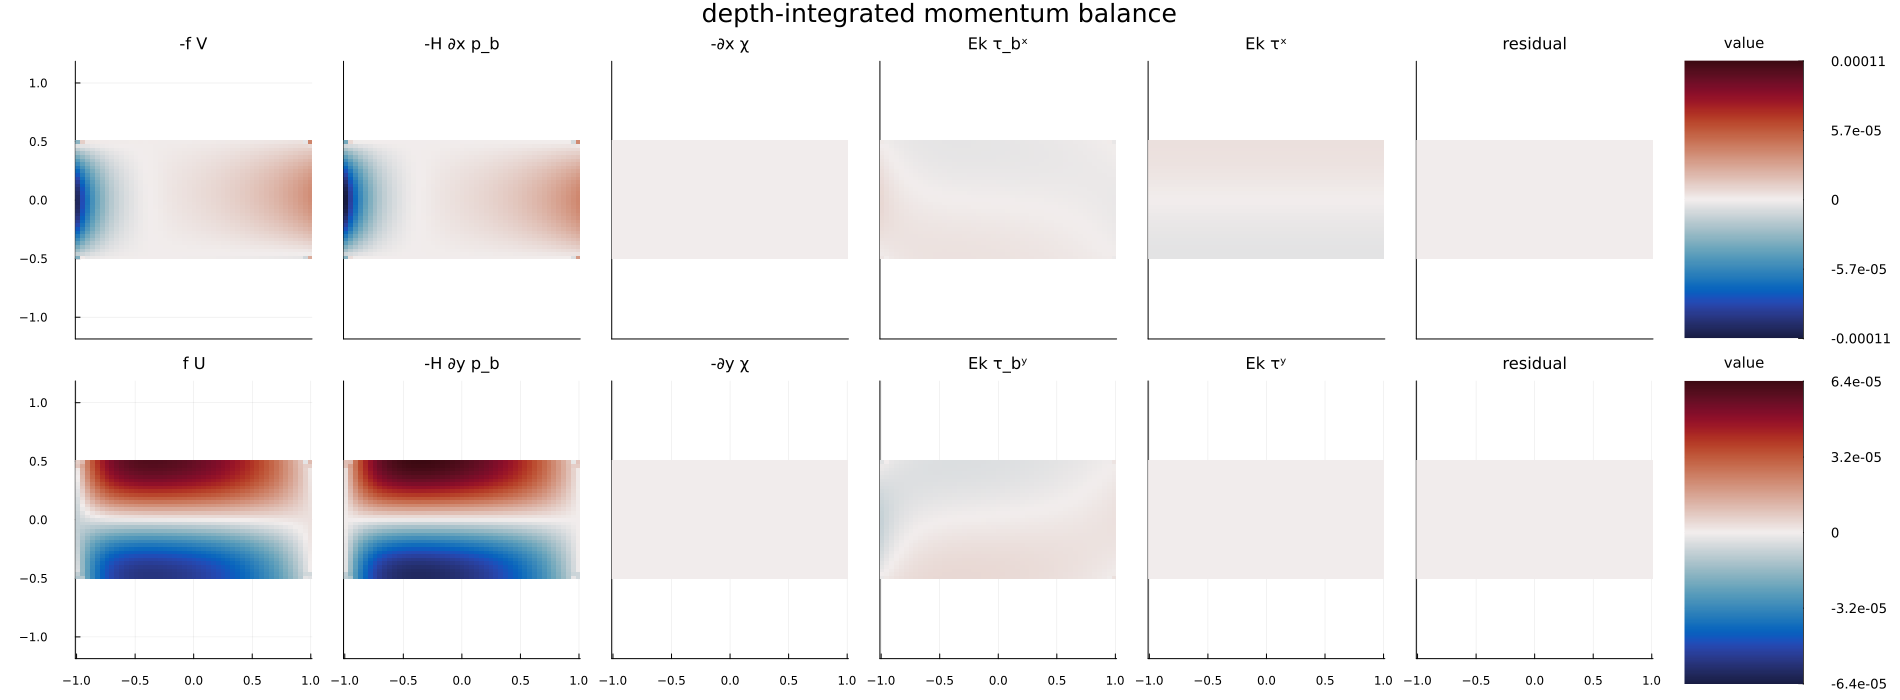

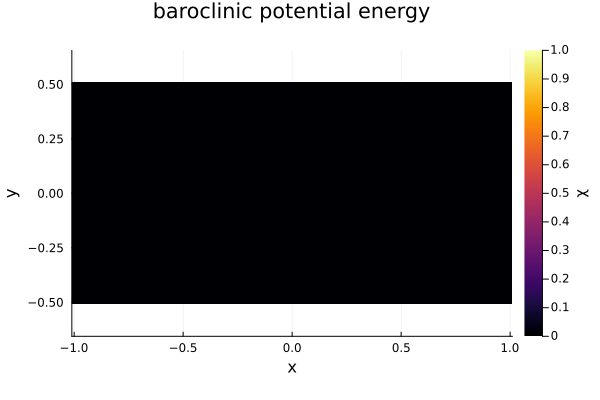

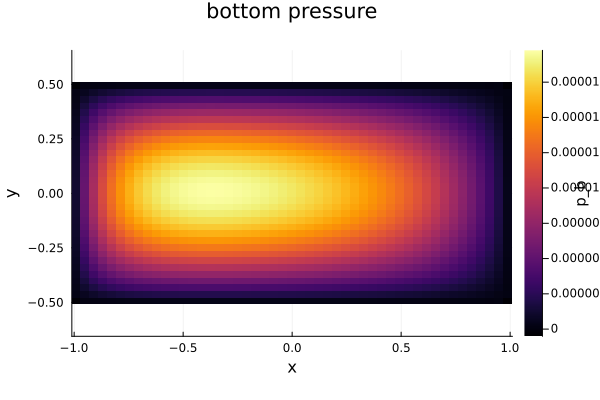

In [6]:
dim_diagnostics = compute_dim_diagnostics(solution, diagnostics)
display(performance_summary(dim_diagnostics))

dim_balance_figure = plot_dim_balance(
    dim_diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_dim_balance.png"),
)
chi_figure = plot_baroclinic_potential_energy(
    dim_diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_chi.png"),
)
bottom_pressure_figure = plot_bottom_pressure(
    dim_diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_bottom_pressure.png"),
)

display(dim_balance_figure)
display(chi_figure)
display(bottom_pressure_figure)

## Barotropic vorticity balance

For this flat-bottom beta-plane problem, the bottom-pressure torque vanishes and equation (36) compares $\beta V$, transport divergence, and the curls of the surface and bottom stresses.

┌ Info: BV diagnostic calculation started
│   Nx = 49
│   Ny = 33
│   wet_points = 1617
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:987
┌ Info: Starting sampling barotropic vorticity terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: BV diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 33
│   percent = 3.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1002
┌ Info: BV diagnostic sampling progress
│   rows_completed = 4
│ 

(sampling = (seconds = 0.067336791, allocated_mib = 141.10580444335938, gc_seconds = 0.013380583), total_seconds = 0.06758809089660645, relative_l2_residual = 1.074596230063682)

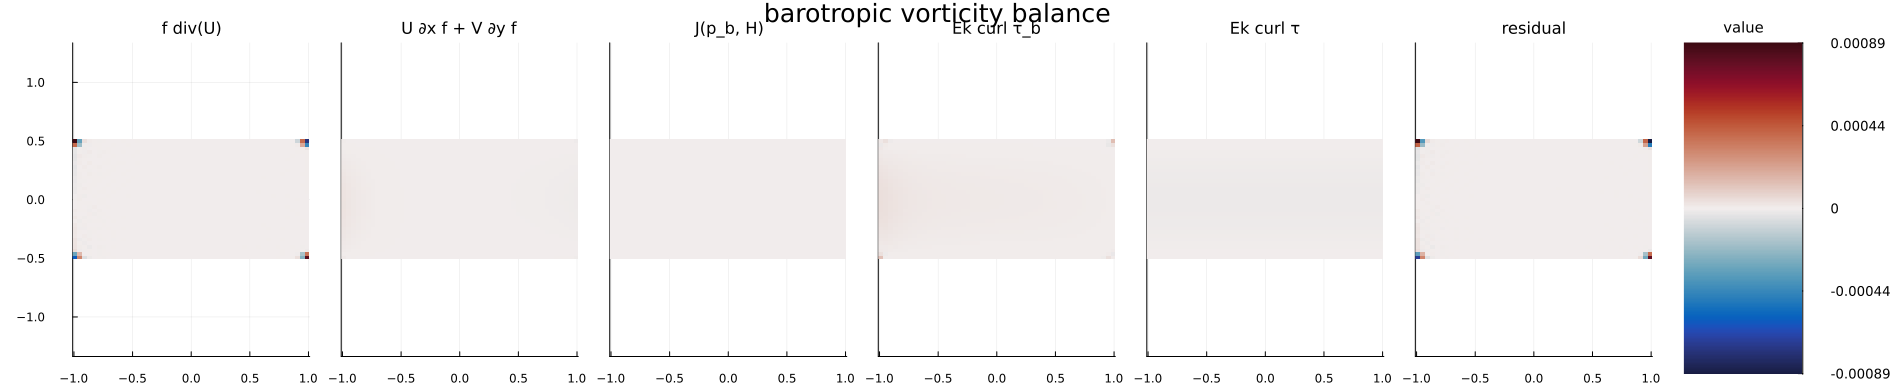

In [7]:
barotropic_vorticity_diagnostics =
    compute_barotropic_vorticity_diagnostics(solution, diagnostics)
display(performance_summary(barotropic_vorticity_diagnostics))

barotropic_vorticity_figure = plot_barotropic_vorticity_balance(
    barotropic_vorticity_diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_barotropic_vorticity_balance.png"),
)
display(barotropic_vorticity_figure)

## Depth-integrated vorticity balance

For this flat-bottom beta-plane problem, $w|_{z=-H}=0$, so equation (41) reduces to a balance between $\beta V$ and the curls of the surface and bottom stresses.

┌ Info: Vorticity diagnostic calculation started
│   Nx = 49
│   Ny = 33
│   wet_points = 1617
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1107
┌ Info: Starting sampling depth-integrated vorticity terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Vorticity diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 33
│   percent = 3.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1137
┌ Info: Vorticity diagnostic sampling progre

(sampling = (seconds = 0.326924417, allocated_mib = 186.95692443847656, gc_seconds = 0.019487917), total_seconds = 0.32720279693603516, relative_l2_residual = 0.393840925529024)

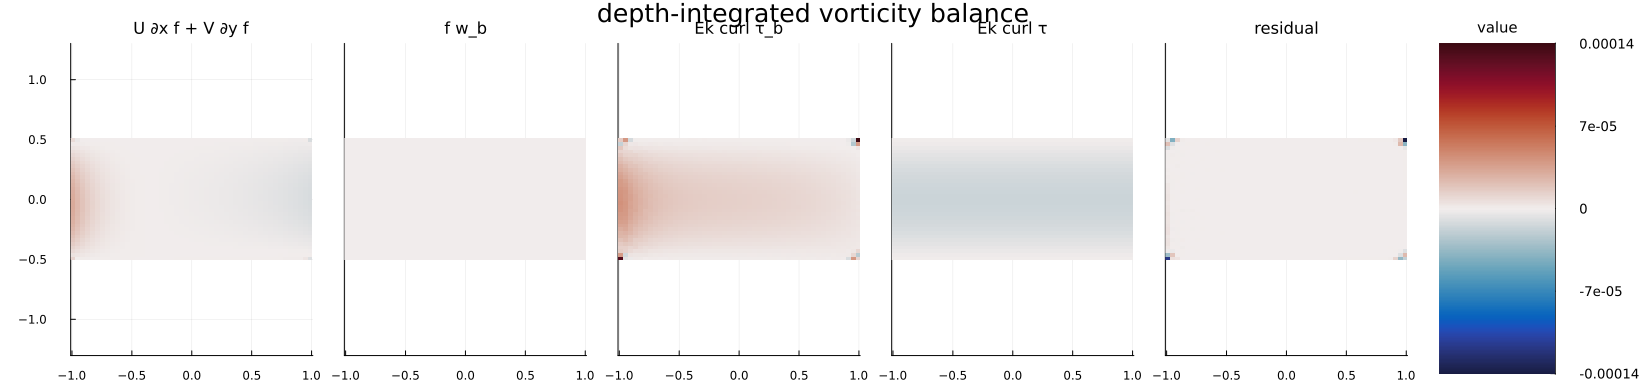

In [8]:
vorticity_diagnostics = compute_vorticity_diagnostics(solution, diagnostics)
display(performance_summary(vorticity_diagnostics))

vorticity_figure = plot_vorticity_balance(
    vorticity_diagnostics;
    output=joinpath(@__DIR__, "stommel_pg_vorticity_balance.png"),
)
display(vorticity_figure)

## Sverdrup-interior comparison

Away from the western boundary, $V_{Sv}=\operatorname{curl}(\tau)/\beta$. Integrating $\partial_x\Psi_{Sv}=V_{Sv}$ from the eastern boundary gives an interior streamfunction that does not satisfy the western no-normal-flow condition. The difference from the PG solution therefore highlights the frictional western boundary layer.

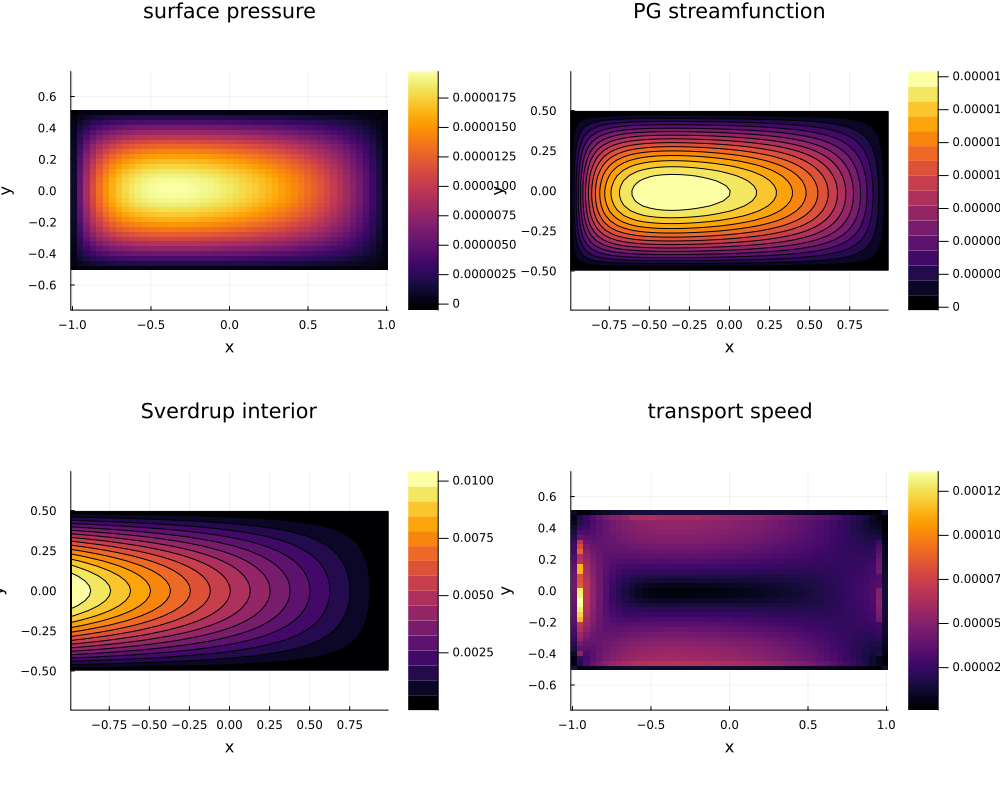

In [9]:
surface_pressure_values = [surface_pressure(solution, xx, yy) for xx in x, yy in y]
sverdrup_V = [wind_curl(xx, yy) / beta for xx in x, yy in y]
sverdrup_streamfunction = [
    (xx - Lx / 2) * wind_curl(xx, yy) / beta for xx in x, yy in y
]
transport_speed = hypot.(diagnostics.transport_U, diagnostics.transport_V)

p1 = heatmap(x, y, surface_pressure_values';
    title="surface pressure", xlabel="x", ylabel="y", aspect_ratio=:equal)
p2 = contourf(x, y, diagnostics.streamfunction';
    title="PG streamfunction", xlabel="x", ylabel="y", aspect_ratio=:equal)
p3 = contourf(x, y, sverdrup_streamfunction';
    title="Sverdrup interior", xlabel="x", ylabel="y", aspect_ratio=:equal)
p4 = heatmap(x, y, transport_speed';
    title="transport speed", xlabel="x", ylabel="y", aspect_ratio=:equal)
comparison_figure = plot(p1, p2, p3, p4; layout=(2, 2), size=(1000, 800))
savefig(comparison_figure, joinpath(@__DIR__, "stommel_pg_sverdrup_comparison.png"))
display(comparison_figure)

In [10]:
western = x .< -Lx / 4
eastern = x .> Lx / 4
western_peak = maximum(transport_speed[western, :])
eastern_peak = maximum(transport_speed[eastern, :])
western_intensification = western_peak / eastern_peak
display((; western_peak, eastern_peak, western_intensification))

(western_peak = 0.0001362465853733301, eastern_peak = 5.108808509531074e-5, western_intensification = 2.6668955220996504)